In [1]:
import sys
!{sys.executable} -m pip install statsmodels

In [2]:
!conda install -y statsmodels

Jupyter detected...
3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: C:\Users\pvper\anaconda3

  added / updated specs:
    - statsmodels


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2026.11.5  |       h382c6e5_0         113 KB
    certifi-2026.10.23         |     pyhd3eb1b0_1         131 KB
    ------------------------------------------------------------
                                           Total:         244 KB

The following packages will be UPDATED:

  ca-certificates    pkgs/main/win-64::ca-certificates-202~ --> pkgs/main/noarch::ca-certificates-2026.11.5-h382c6e5_0 
  certifi            pkgs/main/win-64::certifi-2025.10.5-p~ --> pkgs/main/noarch::certifi-2026.10.23-pyhd3eb1b0_1 



certifi-2026.10.23   | 131 KB    |            |   0% 




==> WARNING: A newer version of conda exists. <==
    current version: 25.5.1
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c defaults conda




In [2]:
!pip install statsmodels

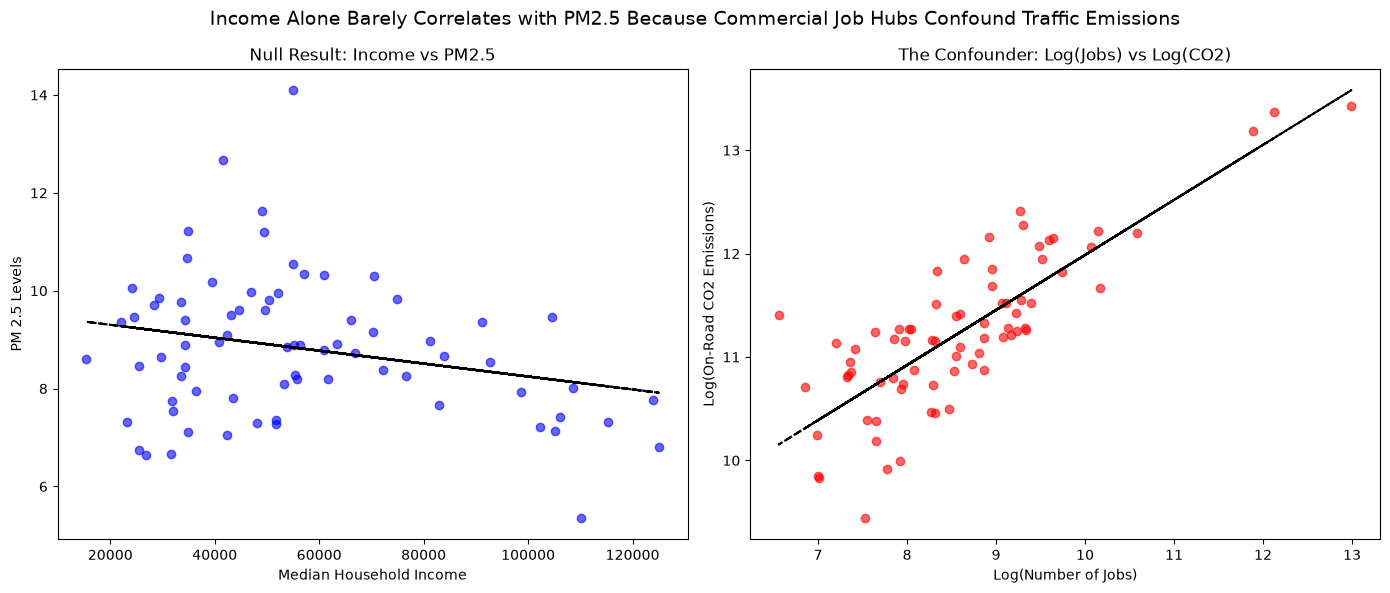

Correlation between Income and PM2.5: -0.248

Log-Log Model R-squared (Jobs vs CO2): 0.663
P-value for Jobs: 6.666397386252731e-19


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import os

if not os.path.exists('figures'):
    os.makedirs('figures')

# 1. Load the datasets
df_demo = pd.read_csv('Chicago_Community_Population_Data.csv')
df_air = pd.read_csv('Open_Air_Chicago_Day_Aggregations_sample_20260928.csv')
df_emis = pd.read_csv('CommunityAreas_LocalEmission2019.csv')

# 2. Fix the Community Columns so they all match 'COMMUNITY'
# Rename demo column
df_demo = df_demo.rename(columns={'Community Area': 'COMMUNITY'})

# Extract the community name from the air sensor by removing trailing numbers, then uppercase it
df_air['COMMUNITY'] = df_air['sensor_name'].str.replace(r'\s*\d+$', '', regex=True).str.upper()

# 3. Group the daily Open Air data by Community to get the average PM2.5
df_air_grouped = df_air.groupby('COMMUNITY')['pm2_5concmass24hourmean_value'].mean().reset_index()

# 4. Merge all three datasets smoothly
df_merged = df_demo.merge(df_air_grouped, on='COMMUNITY').merge(df_emis, on='COMMUNITY')

# 5. Build the Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: Income vs PM2.5 (Using df_emis INCOME)
x_income = df_merged['INCOME']
y_pm25 = df_merged['pm2_5concmass24hourmean_value']

axes[0].scatter(x_income, y_pm25, alpha=0.6, color='blue')
m, b = np.polyfit(x_income, y_pm25, 1)
axes[0].plot(x_income, m*x_income + b, color='black', linestyle='--')
axes[0].set_title('Null Result: Income vs PM2.5')
axes[0].set_xlabel('Median Household Income')
axes[0].set_ylabel('PM 2.5 Levels')

# Panel 2: Jobs vs On-Road CO2 (Log-Log Model)
x_jobs_log = np.log(df_merged['JOBS'])
y_co2_log = np.log(df_merged['ONROAD_CO2'])

axes[1].scatter(x_jobs_log, y_co2_log, alpha=0.6, color='red')
m2, b2 = np.polyfit(x_jobs_log, y_co2_log, 1)
axes[1].plot(x_jobs_log, m2*x_jobs_log + b2, color='black', linestyle='--')
axes[1].set_title('The Confounder: Log(Jobs) vs Log(CO2)')
axes[1].set_xlabel('Log(Number of Jobs)')
axes[1].set_ylabel('Log(On-Road CO2 Emissions)')

plt.suptitle('Income Alone Barely Correlates with PM2.5 Because Commercial Job Hubs Confound Traffic Emissions', fontsize=14)
plt.tight_layout()

# Save the figure so you can upload it to GitHub
plt.savefig('figures/finding-four.png', dpi=300)
plt.show()

# 6. Prove the Stats
income_pm25_corr = x_income.corr(y_pm25)
print("Correlation between Income and PM2.5:", round(income_pm25_corr, 3))

X_log_const = sm.add_constant(x_jobs_log)
log_model = sm.OLS(y_co2_log, X_log_const).fit()
print("\nLog-Log Model R-squared (Jobs vs CO2):", round(log_model.rsquared, 3))
print("P-value for Jobs:", log_model.pvalues['JOBS'])